# T1 Comprender
**Autora:** Jia Xi Shan
**Proyecto P2:** Auditar e integrar un detector de intrusiones con IA

## Base común (todos)
> **No la modifiquéis.** Este cuaderno está en `Proyecto2/notebooks/`, pero `logtools.py` y los datos (`auth.log`, `etiquetas.csv`) están en `Proyecto2/`. Esta celda hace que el cuaderno trabaje desde esa carpeta, para que todo funcione igual que en el cuaderno original del kit.

In [1]:
# --- BASE COMÚN (no modificar) ---
import os
import sys
from pathlib import Path

# Si el cuaderno se abre desde notebooks/, subimos a la carpeta Proyecto2/.
# Se comprueba antes para que ejecutar la celda dos veces no suba dos carpetas.
if Path.cwd().name == "notebooks":
    os.chdir("..")

# Así Python encuentra logtools.py al hacer el import.
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

print("Carpeta de trabajo:", os.getcwd())
print("¿Está auth.log?", Path("auth.log").exists())

Carpeta de trabajo: C:\Users\Tarde\ProyectosPython\Proyecto2
¿Está auth.log? True


# Proyecto DAM — Cuaderno T1: comprender el detector de intrusiones

Este cuaderno se usa para comprender el detector y contestar las preguntas asignadas a T1.

**Antes de empezar**

1. Desde la carpeta `Proyecto2/`, genera los datos con la semilla del grupo:
   `python generar_logs.py --seed 21 --salida auth.log --etiquetas etiquetas.csv`
2. Ejecuta las celdas en orden.
3. Lee las preguntas y escribe las respuestas con tus palabras.
4. Para P6, P7, P8 y P11, usa los resultados reales que aparecen al ejecutar el cuaderno. No inventes cifras ni ejemplos.


## 0. Preparación

In [2]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from logtools import cargar_etiquetas, cargar_log, construir_features

RUTA_LOG = "auth.log"
RUTA_ETIQUETAS = "etiquetas.csv"

## 1. Del texto del log a una tabla

La función `cargar_log` (en `logtools.py`) lee cada línea del fichero, extrae sus datos con expresiones regulares y los guarda en un `DataFrame`.

In [3]:
df = cargar_log(RUTA_LOG)
df.head(10)

12425 eventos cargados; 0 lineas ignoradas


,timestamp,tipo,usuario,ip,puerto,usuario_invalido
0,2026-10-07 00:00:00,acceso_ok,backup,10.0.0.5,43662,False
1,2026-10-07 00:05:25,usuario_invalido,mysql,203.0.113.226,44570,True
2,2026-10-07 00:05:25,fallo_password,mysql,203.0.113.226,44570,True
3,2026-10-07 00:06:56,fallo_password,root,198.51.100.131,53992,False
4,2026-10-07 00:07:46,usuario_invalido,git,203.0.113.15,58764,True
5,2026-10-07 00:07:46,fallo_password,git,203.0.113.15,58764,True
6,2026-10-07 00:08:59,usuario_invalido,test,203.0.113.122,58091,True
7,2026-10-07 00:08:59,fallo_password,test,203.0.113.122,58091,True
8,2026-10-07 00:09:01,usuario_invalido,guest,203.0.113.122,41748,True
9,2026-10-07 00:09:01,fallo_password,guest,203.0.113.122,41748,True


In [4]:
df["tipo"].value_counts()

tipo
fallo_password      5972
usuario_invalido    4883
conexion_cerrada     905
acceso_ok            665
Name: count, dtype: int64

❓ **P1.** ¿Qué representa cada fila de `df`? ¿Qué columnas tiene y qué significa cada una?

Cada fila de df representa un evento del archivo auth.log que el programa ha podido leer. La función cargar_log() convierte las líneas del archivo en una tabla para poder analizarlas.

Las columnas son:
- timestamp: la fecha y la hora del evento.
- tipo: el tipo de evento, como un fallo de contraseña o un acceso correcto.
- usuario: el nombre de usuario que se ha utilizado.
- ip: la dirección IP desde la que se intenta acceder.
- puerto: el puerto utilizado en la conexión.
- usuario_invalido: indica si el usuario es inválido.
En el resultado se han cargado 12.425 eventos y no se ha ignorado ninguna línea.

❓ **P2.** Abre `logtools.py` y localiza `PATRON_LINEA`. Explica con tus palabras qué trozo de la línea captura.

PATRON_LINEA sirve para separar cada línea del log en diferentes partes:

- mes: captura el mes, por ejemplo, Oct.
- dia: captura el día del mes.
- hora: captura la hora, los minutos y los segundos.
- host: captura el nombre del equipo, en este caso srv-web01.
- pid: captura el identificador del proceso SSH.
- msg: captura el mensaje del evento, por ejemplo, un fallo de contraseña.
 
Así, el programa puede separar la información de cada línea y después analizar el mensaje para obtener otros datos, como el usuario y la IP.

❓ **P3.** El log de syslog no trae el año. ¿Cómo lo resuelve el código y qué problema podría dar con un log que cruce el 31 de diciembre?

En logtools.py, el año se fija con la variable ANIO = 2026. Cuando el programa crea la fecha de cada evento, utiliza ese año porque el log original no lo incluye.

El problema es que, si el registro contiene eventos de dos años diferentes, el programa asignaría 2026 a todos. Por ejemplo, un evento del 1 de enero podría quedar antes que uno del 31 de diciembre al ordenar las fechas, aunque en realidad haya ocurrido después. Esto también podría afectar al cálculo del tiempo entre eventos.

## 2. Características por IP

Un modelo de IA no entiende líneas de texto: necesita **una fila de números por cada cosa que queremos clasificar**. Aquí clasificamos direcciones IP, así que `construir_features` resume lo que ha hecho cada IP.

In [5]:
X = construir_features(df)
X.head()

,n_eventos,n_fallos,n_ok,n_usuarios,n_inv,duracion_min,ratio_fallos,fallos_por_min,es_interna,max_fallos_5min,hora_media
ip,,,,,,,,,,,
10.0.0.5,24,0,24,1,0,1383.000000,0.0,0.000000,1,0,11.5
10.0.1.1,1,0,1,1,0,0.000000,0.0,0.000000,1,0,11.0
10.0.1.10,4,2,2,1,0,247.900000,0.5,0.008068,1,2,13.0
10.0.1.11,3,3,0,1,0,0.416667,1.0,3.000000,1,3,7.0
10.0.1.12,5,1,4,1,0,384.483333,0.2,0.002601,1,1,11.6


In [6]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
n_eventos,384.0,32.356771,89.313192,1.0,3.000000,5.000000,11.000000,543.0
n_fallos,384.0,15.552083,40.768177,0.0,0.000000,2.000000,8.000000,247.0
n_ok,384.0,1.731771,1.775502,0.0,1.000000,1.000000,3.000000,24.0
n_usuarios,384.0,2.703125,3.621143,1.0,1.000000,1.000000,1.000000,12.0
n_inv,384.0,25.432292,82.311264,0.0,0.000000,0.000000,0.000000,494.0
duracion_min,384.0,276.152300,364.872045,0.0,1.404167,170.816667,384.991667,1407.9
ratio_fallos,384.0,0.385966,0.333321,0.0,0.000000,0.444444,0.578571,1.0
fallos_por_min,384.0,4.267150,11.823057,0.0,0.000000,0.007208,0.143926,55.0
es_interna,384.0,0.687500,0.464117,0.0,0.000000,1.000000,1.000000,1.0
max_fallos_5min,384.0,12.604167,37.923650,0.0,0.000000,1.000000,3.000000,213.0


❓ **P4.** ¿Qué representa ahora cada fila? ¿Por qué se agrupa por IP y no por usuario o por evento?

Cada fila de X representa una dirección IP y resume su actividad en el log mediante 11 características numéricas.

Se agrupa por IP porque queremos analizar todo lo que ha hecho cada dirección, no solo un evento aislado. Una misma IP puede probar diferentes usuarios y realizar muchos intentos de acceso, por eso es mejor estudiar su actividad completa.

❓ **P5.** Antes de mirar los resultados del modelo, elige **tres características** que creas que mejor distinguen a un atacante de un usuario normal y justifica por qué.

Antes de mirar los resultados, elegiría estas tres características:
- n_fallos: si una IP tiene muchos fallos de contraseña, podría estar intentando adivinar una contraseña.

- n_usuarios: si prueba muchos nombres de usuario diferentes, podría estar buscando una cuenta válida.

- max_fallos_5min: indica el máximo número de fallos de contraseña en cinco minutos, por lo que puede ayudar a detectar muchos intentos en poco tiempo.

Las elegiría porque muestran la cantidad de fallos, los usuarios que se prueban y la rapidez de los intentos. Después tengo que comparar esta idea con los gráficos para ver si realmente se cumple.

## 3. ¿Cuántos atacantes hay y en qué se diferencian?

In [7]:
y = cargar_etiquetas(RUTA_ETIQUETAS, X.index)
print(y.value_counts().rename({0: "legítimas", 1: "atacantes"}))
print(f"Proporción de atacantes: {y.mean():.0%}")

etiqueta
legítimas    284
atacantes    100
Name: count, dtype: int64
Proporción de atacantes: 26%


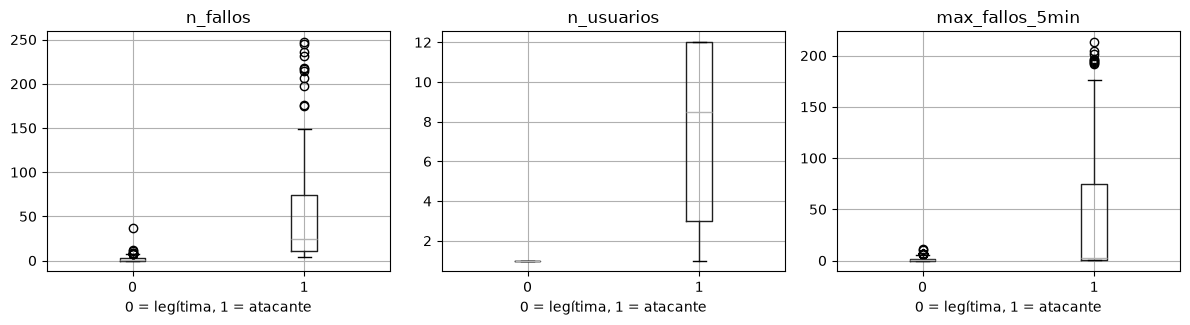

In [8]:
fig, ejes = plt.subplots(1, 3, figsize=(12, 3.5))
for eje, col in zip(ejes, ["n_fallos", "n_usuarios", "max_fallos_5min"]):
    X.assign(etiqueta=y).boxplot(column=col, by="etiqueta", ax=eje)
    eje.set_title(col)
    eje.set_xlabel("0 = legítima, 1 = atacante")
plt.suptitle("")
plt.tight_layout()
plt.show()

❓ **P6.** ¿Coinciden las tres características que elegiste en P5 con lo que ves en los gráficos? ¿Alguna te ha sorprendido?

Sí, en general las tres características parecen útiles para distinguir a los atacantes de las IP legítimas. En los datos, la mediana de n_fallos es 1 para las IP legítimas y 24 para los atacantes. En n_usuarios, las medianas son 1 y 8,5, respectivamente. Para max_fallos_5min, son 1 y 3.

Lo que me parece interesante es que la diferencia en max_fallos_5min es menor que en las otras dos características. Esto demuestra que no todas las características separan igual de bien los dos grupos y que es mejor combinarlas.

❓ **P7.** Hay IPs legítimas con muchos fallos y atacantes con pocos. Localiza al menos un caso de cada tipo en `X` (pista: `X[(y == 0) & (X["n_fallos"] > 10)]`) y explica por qué engañan a una regla sencilla.

Un ejemplo de IP legítima es 192.168.1.249. Tiene 37 fallos de contraseña, pero pertenece a un script de monitorización mal configurado.

Un ejemplo de IP atacante es 192.168.2.45. Tiene 4 fallos de contraseña, pero ha probado 5 nombres de usuario diferentes.

Estos casos demuestran que no podemos decidir si una IP es atacante mirando solo el número de fallos. La primera podría parecer un ataque aunque sea legítima, mientras que la segunda podría pasar desapercibida si usamos un límite de fallos demasiado alto. Por eso es importante tener en cuenta varias características.

## 4. Entrenar y evaluar el modelo

Se reserva un 25 % de las IPs para **examinar** el modelo con datos que no ha visto durante el entrenamiento.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=42)

modelo = RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42)
modelo.fit(X_train, y_train)

pred = modelo.predict(X_test)
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred, digits=3))

[[71  0]
 [ 0 25]]
              precision    recall  f1-score   support

           0      1.000     1.000     1.000        71
           1      1.000     1.000     1.000        25

    accuracy                          1.000        96
   macro avg      1.000     1.000     1.000        96
weighted avg      1.000     1.000     1.000        96



❓ **P8.** Lee la matriz de confusión: ¿cuántos usuarios legítimos habrían sido bloqueados por error (falsos positivos)? ¿Y cuántos atacantes se han colado (falsos negativos)? ¿Qué error es más grave en un servidor real y por qué?

La matriz de confusión obtenida es:

[[71, 0], [0, 25]]

Según este resultado, hay 0 falsos positivos, es decir, ninguna IP legítima se ha clasificado como atacante. También hay 0 falsos negativos, por lo que no se ha escapado ningún atacante en este conjunto de prueba.

En un servidor real, los dos errores son importantes. Un falso positivo puede perjudicar a un usuario legítimo, mientras que un falso negativo puede dejar pasar un ataque. Si el objetivo es la seguridad, un falso negativo puede ser especialmente peligroso. De todas formas, el resultado perfecto de esta prueba no garantiza que el modelo vaya a funcionar igual con datos reales.

❓ **P9.** ¿Qué hacen `stratify=y` y `class_weight="balanced"`? ¿Qué pasaría sin ellos?

stratify=y mantiene una proporción parecida de IP legítimas y atacantes en los datos de entrenamiento y de prueba. Sin esta opción, el reparto podría quedar menos equilibrado.

class_weight="balanced" hace que el modelo tenga en cuenta que hay menos ejemplos de una clase que de otra. Sin esta opción, podría dar más importancia a la clase mayoritaria y detectar peor a los atacantes.

❓ **P10.** ¿Por qué se evalúa con IPs que el modelo no ha visto al entrenar? ¿Qué podría ocurrir si evaluáramos con las mismas?

Según el gráfico de importancia del modelo, las dos características que más pesan son n_eventos y n_usuarios.

Tiene sentido porque una IP que genera muchos eventos o prueba diferentes nombres de usuario puede tener un comportamiento sospechoso. Sin embargo, la importancia de una característica no significa que por sí sola demuestre que existe un ataque.

También hay que tener cuidado con n_ok, porque cuenta los accesos correctos. Si un ataque ya ha conseguido entrar, esta información podría servir como pista, pero llegaría después de que el acceso tuviera éxito. Por eso habría que comprobar si el modelo depende demasiado de esta característica y si podría detectar el ataque antes de que ocurra.

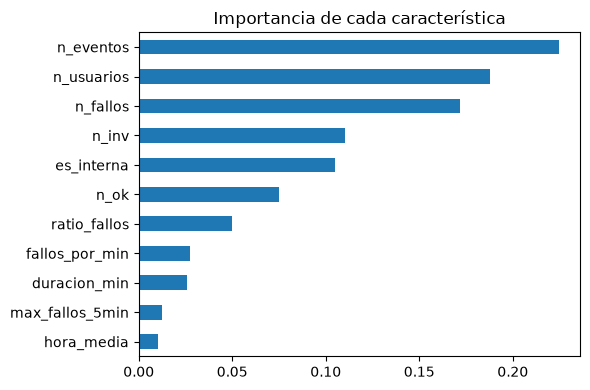

In [10]:
importancias = pd.Series(modelo.feature_importances_, index=X.columns).sort_values()
importancias.plot.barh(figsize=(6, 4), title="Importancia de cada característica")
plt.tight_layout()
plt.show()

❓ **P11.** ¿Qué dos características pesan más? ¿Tiene sentido desde el punto de vista de un administrador? ¿Hay alguna que te haga sospechar (pista: ¿qué pasa si una característica solo existe cuando el ataque ya ha tenido éxito)?

Las dos características con más importancia son n_eventos y n_usuarios. Creo que tiene sentido porque un atacante puede generar muchos eventos y probar diferentes nombres de usuario. También me hace sospechar n_ok, porque cuenta los accesos correctos. Si un ataque ya ha conseguido entrar, detectarlo después puede ser demasiado tarde. De todas formas, el modelo utiliza varias características y no solo una.

## 8. Mi aportación

### Hallazgo
He visto que el sistema no analiza cada intento de conexión por separado, sino que agrupa los eventos por IP y calcula 11 características para cada una. Con estos datos, el modelo intenta distinguir las IP que pueden ser atacantes de las que no lo son. Sin embargo, una IP sospechosa no significa que sea seguro que esté atacando, por lo que hay que revisar los resultados.

### Para el informe
El sistema analiza el registro de autenticación SSH (auth.log) del servidor srv-web01 para encontrar IP que puedan ser sospechosas. Primero lee las líneas del registro y obtiene la información de cada evento. Después agrupa los eventos por IP y calcula 11 características numéricas para cada dirección. El modelo de Machine Learning utiliza estas características para calcular la probabilidad de que una IP sea atacante. La API compara esta probabilidad con un umbral que se puede cambiar y que por defecto es 0,7. Después muestra las IP sospechosas, su probabilidad y el motivo. El sistema no bloquea las IP automáticamente, sino que una persona debe revisar los resultados y tomar la decisión final.

Con la semilla 21, el generador debe crear un registro con 12.425 líneas y un archivo de etiquetas con 384 IP, de las cuales 100 son atacantes. Estas son las cantidades previstas por el proyecto; los resultados del modelo deben comprobarse al ejecutar el cuaderno.

### Para la defensa 
Si un atacante reparte sus intentos entre 500 IP y hace pocos intentos desde cada una, el sistema podría tener más dificultades para detectarlo. Esto ocurre porque algunas características, como el número de fallos por IP o el máximo de fallos en cinco minutos, podrían tener valores bajos. Aunque el modelo utiliza 11 características, eso no significa que vaya a detectar todos los ataques. Para comprobar si detecta este tipo de situación, habría que hacer pruebas y revisar cuántos ataques no consigue detectar. Además, el sistema solo señala las IP sospechosas, así que una persona debe revisar los resultados antes de tomar una decisión.